# Solar filament instance segmentation — full pipeline

Solar Filament Segmentation Challenge 2026 (GONG H-alpha, MAGFiLO). This notebook goes from the
test images to the submission CSV with the weights stored in this repository; nothing is trained here.

| step | what happens | module |
|---|---|---|
| 1 | Preprocess: fit the solar limb, remove limb darkening, z-score the disk | `pipeline/preprocess.py` |
| 2 | Probability map: SAM 2.1 Hiera-B+ encoder with LoRA adapters + FPN decoder, 512 px tiles stitched to the full disk, averaged over 4 mirrored views and five fold models | `pipeline/model.py`, `pipeline/inference.py`, `pipeline/tta.py` |
| 3 | Instances: connected components of the map, kept or dropped by a learned rule | `pipeline/treedecode.py`, `pipeline/keep_rule.py` |
| 4 | Submission CSV: one row per filament, COCO run-length encoding | `pipeline/rle.py`, `pipeline/run.py` |
| 5 | Evaluation: the organisers' self-evaluation metric | `pipeline/scorer.py` |

Inputs used at inference: the test image only. No annotation, no neighbouring frame, no observation
time or station (the file name is used only as the row id).
How the weights were trained: `TRAINING.md`. Why each choice was made, with numbers: `METHODS.md`
and `EXPERIMENTS.md`.

In [1]:
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

REPO = Path.cwd()
assert (REPO / "pipeline").is_dir(), "run this notebook from the repository root"
sys.path.insert(0, str(REPO))

from pipeline import rle, scorer, settings
from pipeline.preprocess import preprocess_jpeg
from pipeline.model import load_fold_model
from pipeline.inference import predict_probability
from pipeline.keep_rule import KeepRule
from pipeline import treedecode as td
from pipeline.run import run, rows_for


def first_existing(*candidates):
    for c in candidates:
        if c and Path(c).exists():
            return Path(c)
    return None


# Where the competition data is. Set the environment variables, or edit the paths.
TEST_DIR = first_existing(os.environ.get("FILAMENT_TEST_DIR"),
                          "/kaggle/input/filament-segmentation-2026/test/test_images",
                          "data/test/test_images")
TRAIN_DIR = first_existing(os.environ.get("FILAMENT_TRAIN_DIR"),
                           "/kaggle/input/filament-segmentation-2026/train/train_images",
                           "data/train/train_images")
TRAIN_JSON = first_existing(os.environ.get("FILAMENT_TRAIN_JSON"),
                            "/kaggle/input/filament-segmentation-2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json",
                            "data/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")
LIMIT = int(os.environ.get("FILAMENT_LIMIT", "0")) or None     # e.g. 4 for a quick check; None = all test images
OUT = REPO / "outputs"
OUT.mkdir(exist_ok=True)
assert TEST_DIR is not None, "set FILAMENT_TEST_DIR to the folder with the test *.jpeg files"
test_files = sorted(TEST_DIR.glob("*.jpeg"))
print(f"test images: {len(test_files)} in {TEST_DIR}")
print(f"device: {'cuda: ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu (slow)'}")
print(f"settings: folds {settings.FOLDS}, test-time views {settings.N_VIEWS}, tile overlap {settings.OVERLAP}, "
      f"candidate level {settings.KEEP_LEVEL}")

test images: 180 in <competition data>/test/test_images
device: cuda: NVIDIA A40
settings: folds (0, 1, 2, 3, 4), test-time views 4, tile overlap 0.5, candidate level 0.45


## Step 1 — Preprocessing

A GONG H-alpha frame is brighter at disk centre than near the limb, and its overall level changes
with station and seeing. Three operations, all computed from the image itself:

1. **Limb fit.** Centre and radius of the solar disk.
2. **Limb-darkening removal.** Divide by the median brightness at each radius, so quiet Sun has the same level everywhere on the disk.
3. **z-score** over the analysis disk (radius 0.95 R). The outer 5 % is excluded: filaments there are foreshortened and sit under the bright rim.

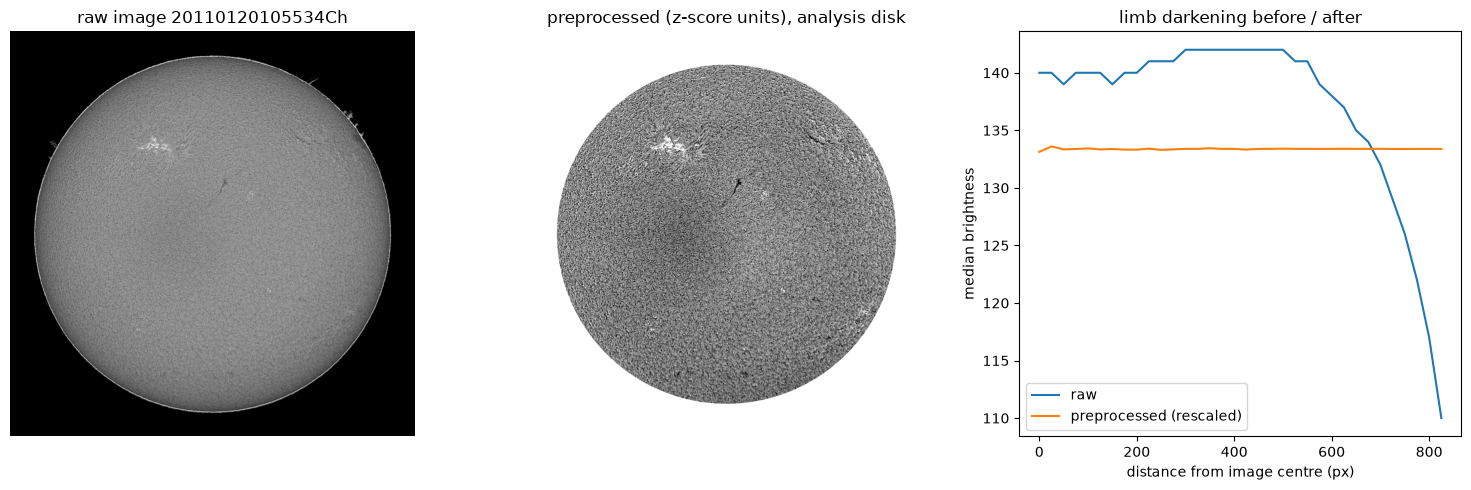

analysis disk covers 55.0% of the frame


In [2]:
example = test_files[0]
from PIL import Image
raw = np.asarray(Image.open(example).convert("L"))
img, valid = preprocess_jpeg(example)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(raw, cmap="gray"); ax[0].set_title(f"raw image {example.stem}")
ax[1].imshow(np.where(valid, img, np.nan), cmap="gray", vmin=-3, vmax=3); ax[1].set_title("preprocessed (z-score units), analysis disk")
r = np.hypot(*np.indices(raw.shape) - np.array(raw.shape)[:, None, None] / 2)
for a, lab in ((raw.astype(float), "raw"), (np.where(valid, img, np.nan) * raw.std() / 3 + raw[valid].mean(), "preprocessed (rescaled)")):
    prof = [np.nanmedian(a[(r >= lo) & (r < lo + 25)]) for lo in range(0, 850, 25)]
    ax[2].plot(range(0, 850, 25), prof, label=lab)
ax[2].set_xlabel("distance from image centre (px)"); ax[2].set_ylabel("median brightness"); ax[2].legend()
ax[2].set_title("limb darkening before / after")
for a in ax[:2]: a.axis("off")
plt.tight_layout(); plt.show()
print(f"analysis disk covers {valid.mean():.1%} of the frame")

## Step 2 — Model and probability map

**Architecture.** The image encoder of SAM 2.1 (Hiera-B+, a hierarchical vision transformer pretrained by
Meta on natural images and video) gives feature maps at four scales. Its 68.6 M weights stay frozen;
low-rank adapters (LoRA, rank 4) on the attention layers and the LayerNorms are trained instead, which lets
707 images adapt a large encoder without overfitting it. A feature-pyramid decoder (FPN) merges the four
scales into one filament-probability map. 5.4 M of 74.1 M weights are trained.

**Training (not run here; see `TRAINING.md`).** Two stages per fold: (A) Dice + centre-line Dice loss;
(B) a fine-tune that adds a per-component loss and selects the checkpoint by validation Panoptic Quality.
Five models, one per fold of a split grouped by observation week.

**Inference.** The 2048 px disk is cut into 512 px tiles with 50 % overlap, tile outputs are averaged back
into one map. This is done for the image and its three mirror images (test-time augmentation: a filament has
no preferred orientation) and for each of the five fold models; all maps are averaged.

In [3]:
RUN_TRAINING = False   # the stored weights are loaded; set True only to see the training commands
if RUN_TRAINING:
    print(open(REPO / "TRAINING.md").read())

t0 = time.time()
loaded = [load_fold_model(f) for f in settings.FOLDS]
models, cfg = [m for m, _ in loaded], loaded[0][1]
n_all = sum(p.numel() for p in models[0].parameters())
manifest = json.loads((REPO / "weights" / "MANIFEST.json").read_text())
print(f"{len(models)} fold models loaded in {time.time() - t0:.0f}s; {n_all / 1e6:.1f} M weights each, "
      f"{manifest['folds']['0']['params'] / 1e6:.2f} M of them trained (stored per fold), the rest is the frozen encoder")
keep = KeepRule()
print(f"keep rule: gradient-boosted regressor on {len(td.FEATS)} features, cut-off tau = {keep.tau:.2f}")

<site-packages>/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5 fold models loaded in 9s; 74.1 M weights each, 5.45 M of them trained (stored per fold), the rest is the frozen encoder


keep rule: gradient-boosted regressor on 22 features, cut-off tau = 0.19


probability map in 13.5s


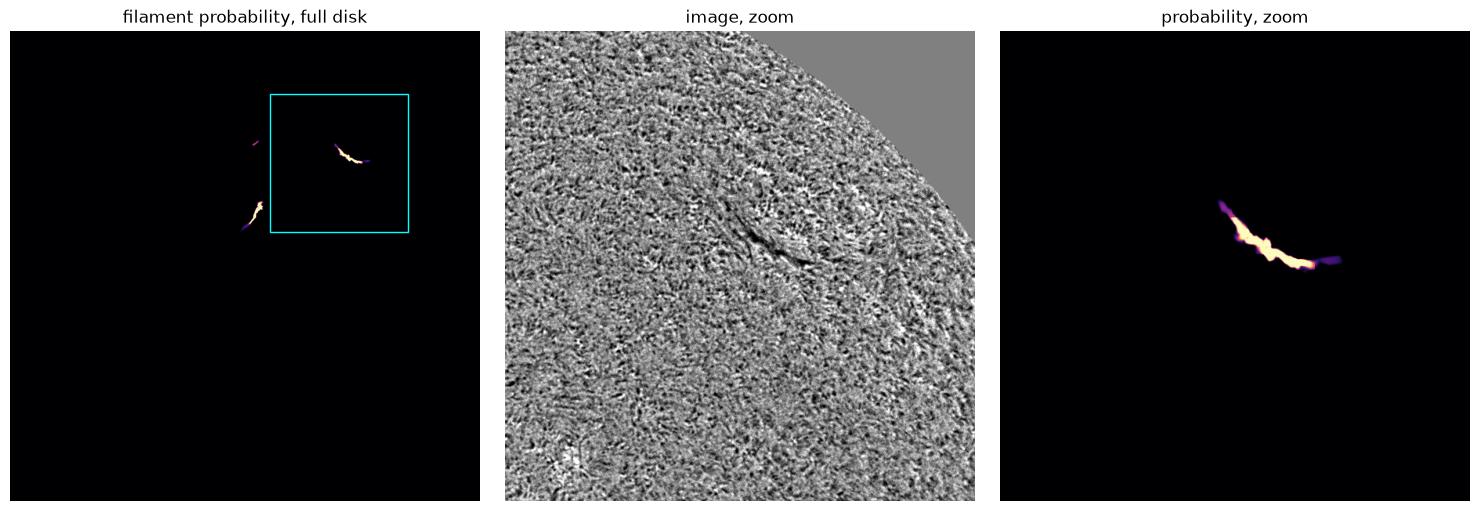

In [4]:
t0 = time.time()
prob = predict_probability(models, cfg, img, valid)
print(f"probability map in {time.time() - t0:.1f}s")
ys, xs = np.nonzero(prob > 0.5)
cy, cx = (int(np.median(ys)), int(np.median(xs))) if len(ys) else (1024, 1024)
y0, x0 = np.clip(cy - 300, 0, 2048 - 600), np.clip(cx - 300, 0, 2048 - 600)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(prob, cmap="magma", vmin=0, vmax=1); ax[0].set_title("filament probability, full disk")
ax[0].add_patch(plt.Rectangle((x0, y0), 600, 600, fill=False, color="cyan"))
ax[1].imshow(img[y0:y0 + 600, x0:x0 + 600], cmap="gray", vmin=-3, vmax=3); ax[1].set_title("image, zoom")
ax[2].imshow(prob[y0:y0 + 600, x0:x0 + 600], cmap="magma", vmin=0, vmax=1); ax[2].set_title("probability, zoom")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Step 3 — From the probability map to filaments

Candidates are the connected components of {probability >= 0.45}. Which candidates should be reported?

Panoptic Quality is `sum of IoU over matched pairs / (TP + FP/2 + FN/2)`. Reporting one more candidate adds
its IoU to the numerator if it matches an annotation, and 1/2 to the denominator whether it matches or not.
So a candidate helps exactly when its **expected IoU** is above PQ/2 (about 0.2).

A gradient-boosted regressor estimates that expected IoU, `q`, from 22 features of the candidate: area,
length, width, elongation, mean / spread / peak of the probability, how dark it is against its surroundings,
its distance from disk centre, and how it behaves at other probability levels (does it split when the level
rises, what does it join when the level drops). Candidates with `q > tau` are kept. The regressor and `tau`
were fitted on out-of-fold maps of the 707 training images (nested cross-validation, `EXPERIMENTS.md`).
Kept components are pixel-disjoint by construction.

3 candidates at level 0.45, 2 kept (q > 0.19)


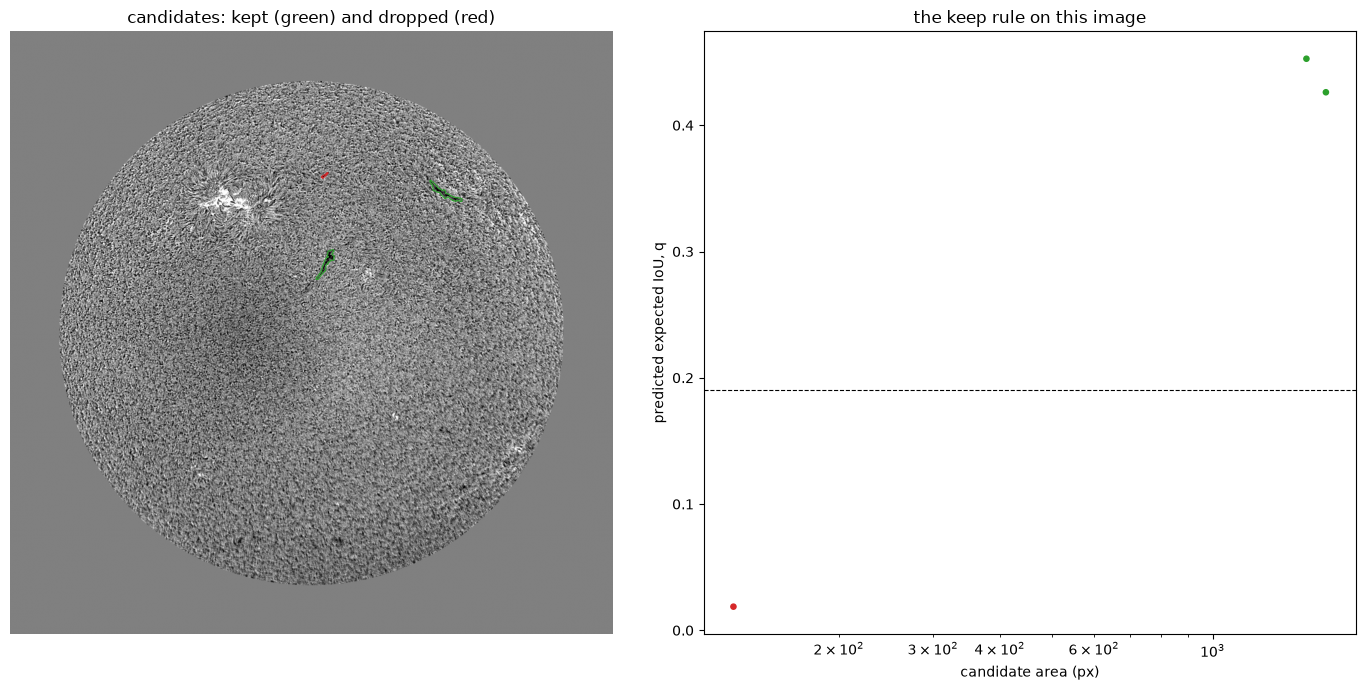

In [5]:
tree = td.build_tree(prob, valid, img)
q = np.clip(keep.model.predict(tree["X"]), 0, 1) if len(tree["area"]) else np.zeros(0)
cand = np.flatnonzero(tree["level"] == keep.level)
lab, n, q_kept = keep.decode(prob, valid, img)
print(f"{len(cand)} candidates at level {settings.KEEP_LEVEL}, {n} kept (q > {keep.tau:.2f})")

from skimage.measure import find_contours
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img, cmap="gray", vmin=-3, vmax=3); ax[0].set_title("candidates: kept (green) and dropped (red)")
cand_map, _ = td.render(tree, cand)
for k, i in enumerate(cand):
    col = "#2ca02c" if q[i] > keep.tau else "#d62728"
    for c in find_contours((cand_map == k + 1).astype(float), 0.5):
        ax[0].plot(c[:, 1], c[:, 0], color=col, lw=0.8)
ax[1].scatter(np.exp(tree["X"][cand, td.FEATS.index("log_area")]), q[cand], c=["#2ca02c" if v > keep.tau else "#d62728" for v in q[cand]], s=14)
ax[1].axhline(keep.tau, color="k", ls="--", lw=0.8); ax[1].set_xscale("log")
ax[1].set_xlabel("candidate area (px)"); ax[1].set_ylabel("predicted expected IoU, q"); ax[1].set_title("the keep rule on this image")
ax[0].axis("off"); plt.tight_layout(); plt.show()

## Step 4 — All test images to the submission CSV

One row per filament: `filament_id = <image id>_<k>`, `segmentation_rle` = COCO run-length counts of its
2048 x 2048 mask (pycocotools).

In [6]:
csv_path = OUT / "submission.csv"
t0 = time.time()
sub = run(TEST_DIR, csv_path, limit=LIMIT)
elapsed = time.time() - t0

  20/180 images, 148 filaments (421s)


  40/180 images, 316 filaments (839s)


  60/180 images, 478 filaments (1258s)


  80/180 images, 673 filaments (1678s)


  100/180 images, 866 filaments (2097s)


  120/180 images, 975 filaments (2515s)


  140/180 images, 1047 filaments (2931s)


  160/180 images, 1101 filaments (3343s)


  180/180 images, 1190 filaments (3760s)


wrote outputs/submission.csv: 1190 filaments on 180 images (20.9 s per image)


In [7]:
# Checks on the file that will be uploaded
sub = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
assert list(sub.columns) == ["filament_id", "segmentation_rle"]
assert sub.filament_id.is_unique
stem = sub.filament_id.str.rsplit("_", n=1).str[0]
n_images = len(test_files[:LIMIT])
assert set(stem) <= {p.stem for p in test_files}
overlapping = 0
for s, g in sub.groupby(stem):
    masks = np.stack([rle.decode(x) for x in g.segmentation_rle])
    overlapping += int((masks.sum(0) > 1).any())
assert overlapping == 0, "masks of one image overlap"
m0 = rle.decode(sub.segmentation_rle.iloc[0]); assert rle.encode(m0) == sub.segmentation_rle.iloc[0]
per = stem.value_counts()
print(f"{len(sub)} filaments on {per.size} of {n_images} images (images with none: {n_images - per.size}); "
      f"per image: median {per.median():.0f}, min {per.min()}, max {per.max()}")
print(f"no overlapping masks, ids unique, RLE round trip exact; {elapsed / max(n_images, 1):.1f} s per image, {elapsed / 60:.1f} min in total")
if torch.cuda.is_available():
    print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB")

1190 filaments on 176 of 180 images (images with none: 4); per image: median 7, min 1, max 18
no overlapping masks, ids unique, RLE round trip exact; 20.9 s per image, 62.7 min in total
peak GPU memory 4.7 GiB


## Step 5 — Evaluation

The test labels are hidden, so quality is measured on the training set by cross-validation: every one of
the 707 training images is predicted by the fold model that never saw it (folds grouped by observation
week), and scored with the organisers' self-evaluation rule against every annotator record. Those numbers
are computed by `experiments/` and stored; the next cell prints them. The cell after it runs the same metric
code (`pipeline/scorer.py`) on a few training images to show how it works — the models have seen those
images in training (four of the five folds), so that number is an illustration, not an estimate.

In [8]:
print(open(REPO / "EXPERIMENTS.md").read().split("## Side measurements")[0])

# Experiment log — try_error (2026-11-13)

Local validation for every row: the 707 competition train disks, each predicted by the fold model that never
saw it (`kaggle/splits/folds_k707_v1.json`: 5 folds, grouped by 7-day observation window), scored with the
official self-evaluation rule against all 1,154 annotator records, counts pooled. Anything fitted on labels
(the keep-rule regressor, its cut-off tau) is nested-cross-fitted: for held-out fold F it is fitted on the
other four folds only. The public leaderboard was not used to choose anything.

Rule for keeping a change (set before the runs): validation PQ improves and neither match count gets worse.
Stop after two consecutive ideas under +0.003.

| # | change (one at a time) | PQ | SQ | RQ | TP / FP / FN | Dice, matched | one-to-many | many-to-one | Δ PQ vs previous kept | kept? |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | baseline: submitted pipeline (kag13 fold model, hysteresis 0.50 -> 0.45, area >= 400, mean p >= 0.85)

6 training images (seen in training - illustration only): PQ 0.478, SQ 0.703, RQ 0.680, TP/FP/FN 35/10/23, mean Dice of overlapping pairs 0.773


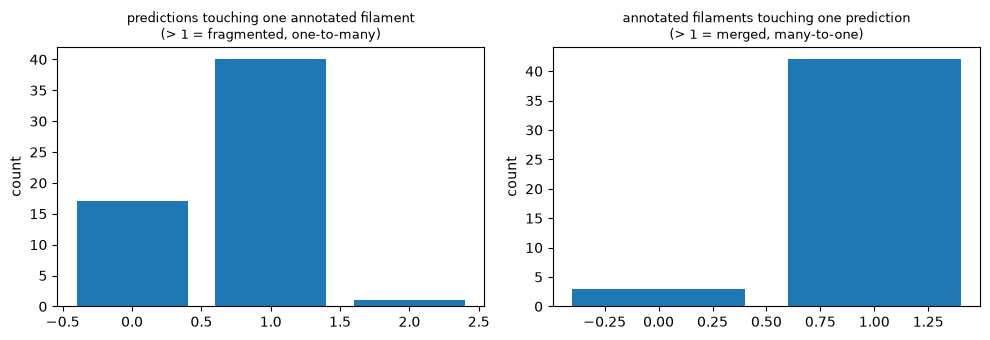

In [9]:
N_DEMO = 6
if TRAIN_DIR is not None and TRAIN_JSON is not None:
    coco = json.loads(TRAIN_JSON.read_text())
    demo_files = sorted(TRAIN_DIR.glob("*.jpeg"))[:: max(1, len(list(TRAIN_DIR.glob('*.jpeg'))) // N_DEMO)][:N_DEMO]
    rows = []
    for p in demo_files:
        im, va = preprocess_jpeg(p)
        lb, k, _ = keep.decode(predict_probability(models, cfg, im, va), va, im)
        rows += rows_for(p.stem, lb, k)
    pred = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    gt = scorer.gt_frame_from_coco(coco, stems={p.stem for p in demo_files})
    s = scorer.score(gt, pred)
    print(f"{len(demo_files)} training images (seen in training - illustration only): PQ {s['pq']:.3f}, SQ {s['sq']:.3f}, "
          f"RQ {s['rq']:.3f}, TP/FP/FN {s['tp']}/{s['fp']}/{s['fn']}, mean Dice of overlapping pairs {s['dice_mean_nonzero']:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for a, key, title in ((ax[0], "gt_degree_hist", "predictions touching one annotated filament\n(> 1 = fragmented, one-to-many)"),
                          (ax[1], "pred_degree_hist", "annotated filaments touching one prediction\n(> 1 = merged, many-to-one)")):
        h = s[key]; a.bar([int(x) for x in h], list(h.values())); a.set_title(title, fontsize=9); a.set_ylabel("count")
    plt.tight_layout(); plt.show()
else:
    print("training images / annotations not found: set FILAMENT_TRAIN_DIR and FILAMENT_TRAIN_JSON to run the metric demo")

## Step 6 — What the predictions look like

Full-disk overlays for a few test images (every predicted filament outlined), then zooms on the largest ones.

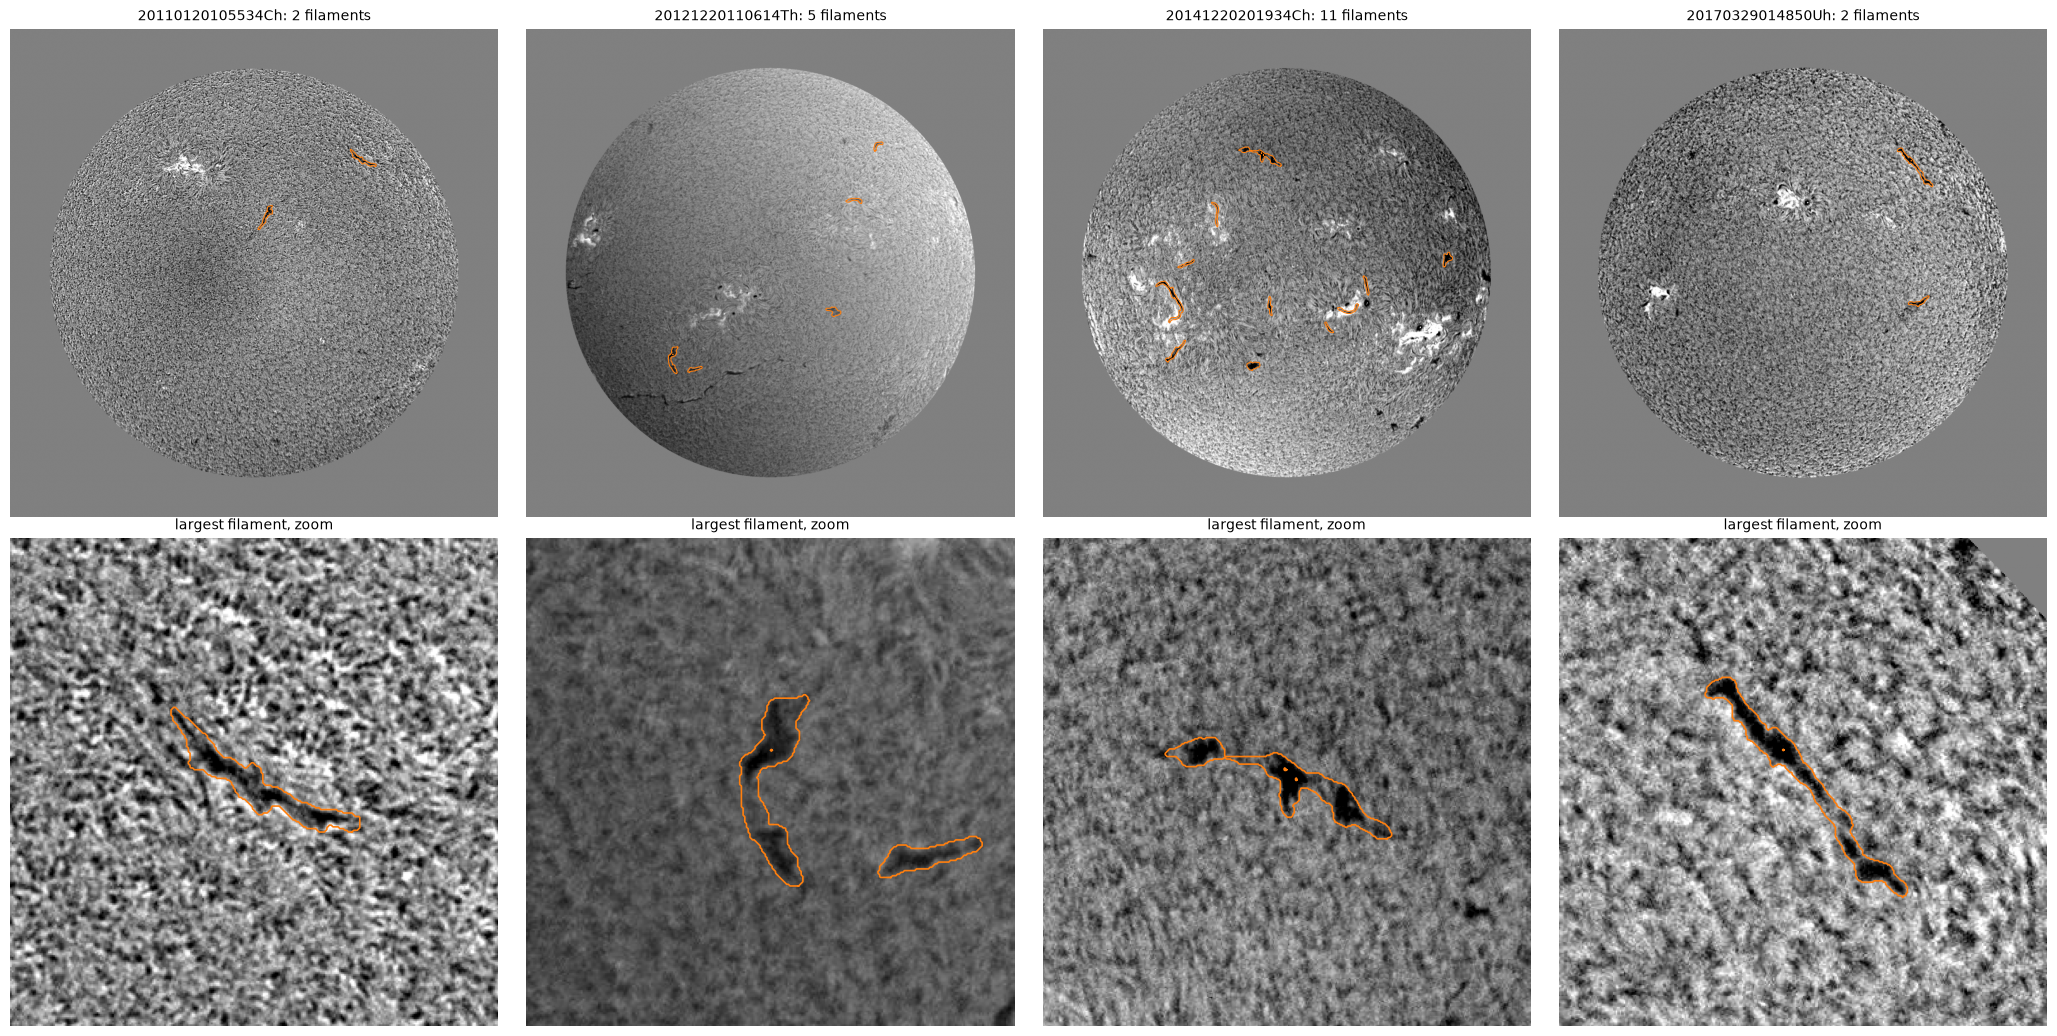

submission file: outputs/submission.csv


In [10]:
show = [p for p in test_files[:LIMIT]][:: max(1, len(test_files[:LIMIT]) // 4)][:4]
fig, axes = plt.subplots(2, len(show), figsize=(5.2 * len(show), 10.4))
axes = np.atleast_2d(axes).reshape(2, -1)
for j, p in enumerate(show):
    im, va = preprocess_jpeg(p)
    g = sub[stem == p.stem]
    lab = np.zeros(im.shape, dtype=np.int32)
    for k, x in enumerate(g.segmentation_rle):
        lab[rle.decode(x)] = k + 1
    axes[0, j].imshow(im, cmap="gray", vmin=-3, vmax=3)
    for k in range(1, len(g) + 1):
        for c in find_contours((lab == k).astype(float), 0.5):
            axes[0, j].plot(c[:, 1], c[:, 0], color="#ff7f0e", lw=0.7)
    axes[0, j].set_title(f"{p.stem}: {len(g)} filaments", fontsize=10); axes[0, j].axis("off")
    if len(g):
        big = int(np.bincount(lab.ravel())[1:].argmax()) + 1
        ys, xs = np.nonzero(lab == big)
        h = int(max(np.ptp(ys), np.ptp(xs)) * 0.75 + 60)
        y0, y1 = max(0, int(ys.mean()) - h), min(2048, int(ys.mean()) + h)
        x0, x1 = max(0, int(xs.mean()) - h), min(2048, int(xs.mean()) + h)
        axes[1, j].imshow(im[y0:y1, x0:x1], cmap="gray", vmin=-3, vmax=3)
        for k in np.unique(lab[y0:y1, x0:x1])[1:]:
            for c in find_contours((lab[y0:y1, x0:x1] == k).astype(float), 0.5):
                axes[1, j].plot(c[:, 1], c[:, 0], color="#ff7f0e", lw=1.2)
    axes[1, j].set_title("largest filament, zoom", fontsize=10); axes[1, j].axis("off")
plt.tight_layout(); plt.show()
print("submission file:", csv_path)